# Step 2: Data Visualization - Car Price Prediction

Here we draw simple charts on the **cleaned** data to understand what affects a car's price.
(Run `01_data_cleaning.ipynb` first so that `cars_cleaned.csv` exists.)

## 1. Import libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")
%matplotlib inline

## 2. Load the clean data

In [2]:
df = pd.read_csv("cars_cleaned.csv")
print(df.shape)
df.head()

(57883, 16)


,Manufacturer,Model,Prod_Year,Category,Leather_Interior,Fuel_Type,Engine_Volume,Mileage,Cylinders,Gear_box_type,Drive_Wheels,Doors,Color,Airbags,Price,Turbo
0,Audi,Q7,2008,SUV,No,Electric,4.4,86140.0,6,Automatic,Front-wheel,5,Grey,1,30396.057968,0
1,Mercedes-Benz,C-Class,2021,Hatchback,No,Petrol,3.6,180266.0,4,Tiptronic,Front-wheel,5,Grey,2,41415.845710,0
2,Kia,Sportage,2008,Coupe,Yes,Electric,1.3,247950.0,6,Automatic,4x4,4,Grey,6,10042.988409,0
3,Ford,Explorer,2008,Minivan,No,Diesel,2.0,172359.0,4,Automatic,4x4,4,Blue,5,7180.349761,0
4,Audi,A6,2015,Hatchback,No,Diesel,3.5,48767.0,4,CVT,Front-wheel,5,Black,5,29688.279552,0


## 3. How are the prices distributed?

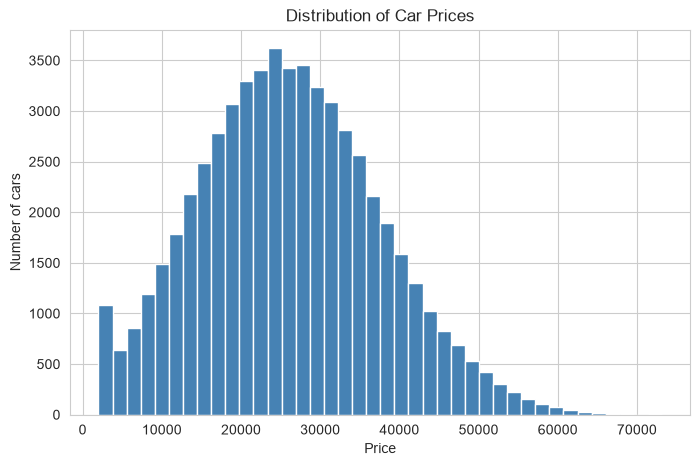

In [3]:
plt.figure(figsize=(8, 5))
plt.hist(df["Price"], bins=40, color="steelblue", edgecolor="white")
plt.title("Distribution of Car Prices")
plt.xlabel("Price")
plt.ylabel("Number of cars")
plt.show()

## 4. Number of cars per manufacturer

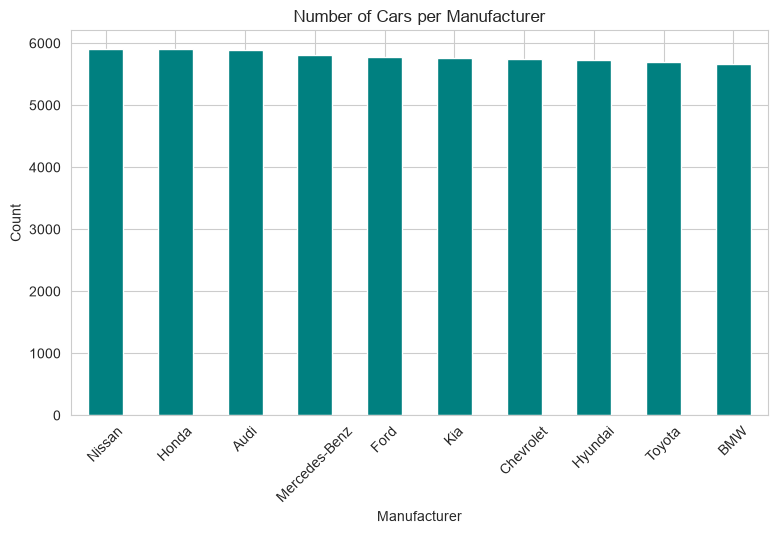

In [4]:
plt.figure(figsize=(9, 5))
df["Manufacturer"].value_counts().plot(kind="bar", color="teal")
plt.title("Number of Cars per Manufacturer")
plt.xlabel("Manufacturer")
plt.ylabel("Count")
plt.xticks(rotation=45)
plt.show()

## 5. Average price by manufacturer

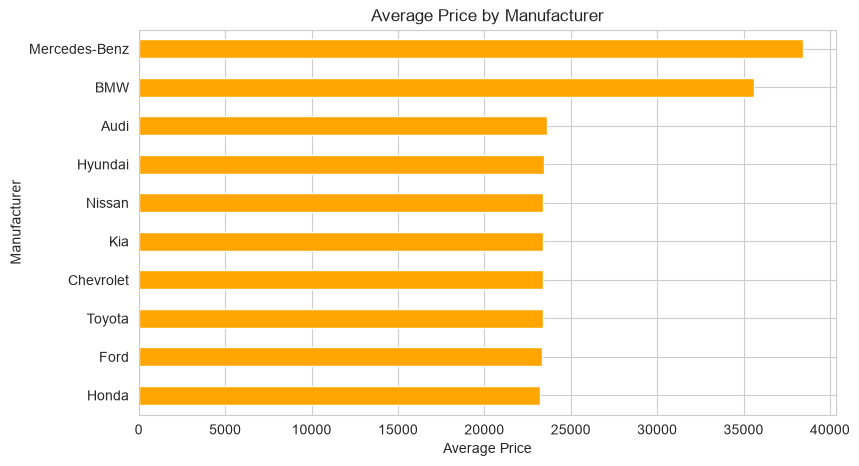

In [5]:
plt.figure(figsize=(9, 5))
df.groupby("Manufacturer")["Price"].mean().sort_values().plot(kind="barh", color="orange")
plt.title("Average Price by Manufacturer")
plt.xlabel("Average Price")
plt.show()

**Insight:** BMW and Mercedes-Benz cars cost much more than the other brands.

## 6. Average price by fuel type

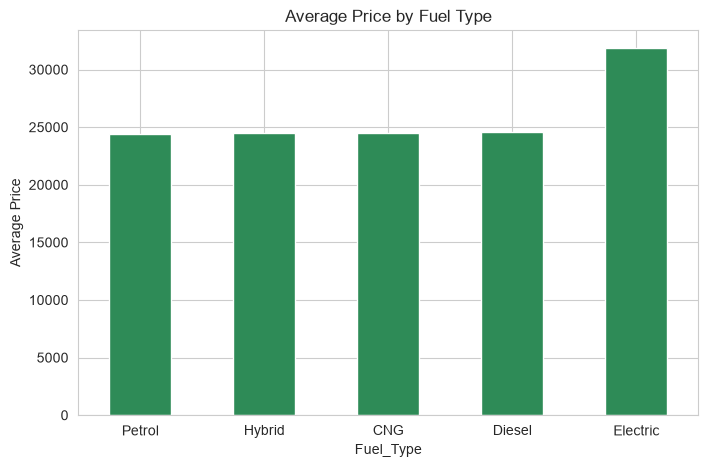

In [6]:
plt.figure(figsize=(8, 5))
df.groupby("Fuel_Type")["Price"].mean().sort_values().plot(kind="bar", color="seagreen")
plt.title("Average Price by Fuel Type")
plt.ylabel("Average Price")
plt.xticks(rotation=0)
plt.show()

**Insight:** Electric cars are clearly more expensive than the other fuel types.

## 7. Price vs production year

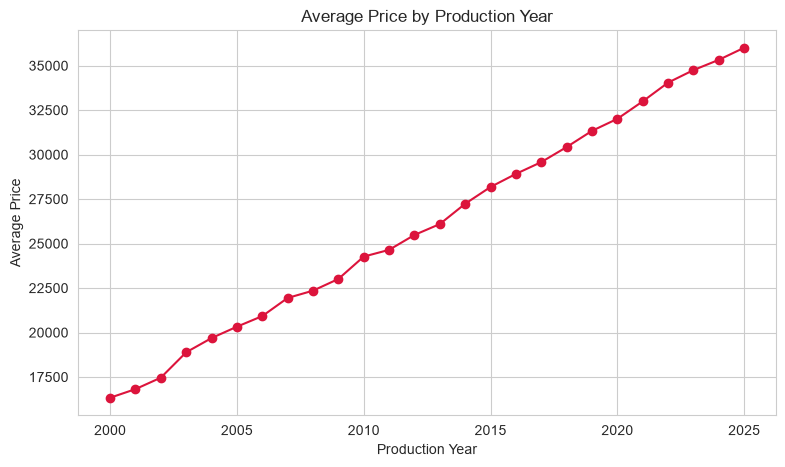

In [7]:
plt.figure(figsize=(9, 5))
df.groupby("Prod_Year")["Price"].mean().plot(marker="o", color="crimson")
plt.title("Average Price by Production Year")
plt.xlabel("Production Year")
plt.ylabel("Average Price")
plt.show()

**Insight:** Newer cars cost more. The price rises steadily with the production year.

## 8. Price vs mileage

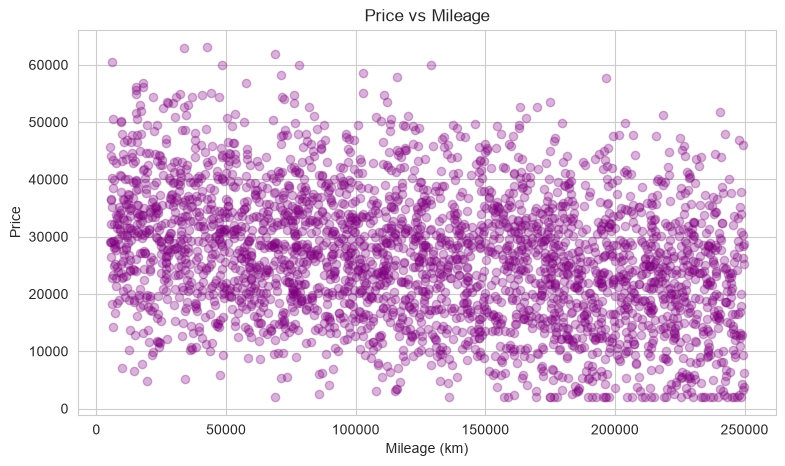

In [8]:
sample = df.sample(3000, random_state=42)   # a sample keeps the chart readable

plt.figure(figsize=(9, 5))
plt.scatter(sample["Mileage"], sample["Price"], alpha=0.3, color="purple")
plt.title("Price vs Mileage")
plt.xlabel("Mileage (km)")
plt.ylabel("Price")
plt.show()

**Insight:** Cars that have run more kilometres tend to be cheaper.

## 9. Price vs engine volume

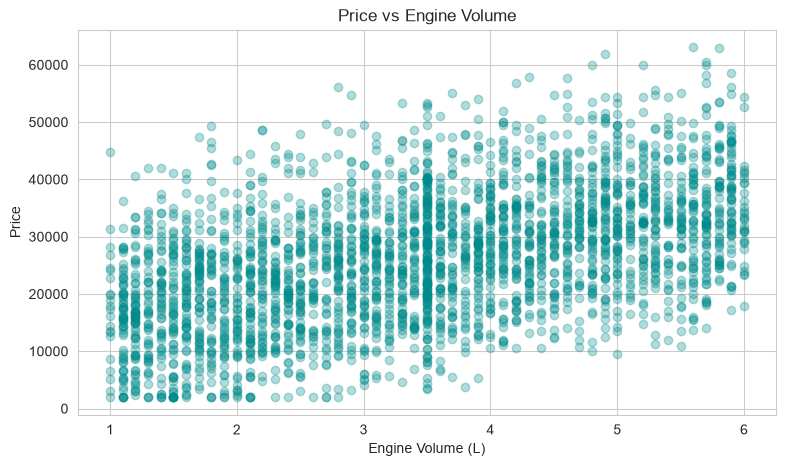

In [9]:
plt.figure(figsize=(9, 5))
plt.scatter(sample["Engine_Volume"], sample["Price"], alpha=0.3, color="darkcyan")
plt.title("Price vs Engine Volume")
plt.xlabel("Engine Volume (L)")
plt.ylabel("Price")
plt.show()

**Insight:** A bigger engine usually means a higher price.

## 10. Price by category (box plot)

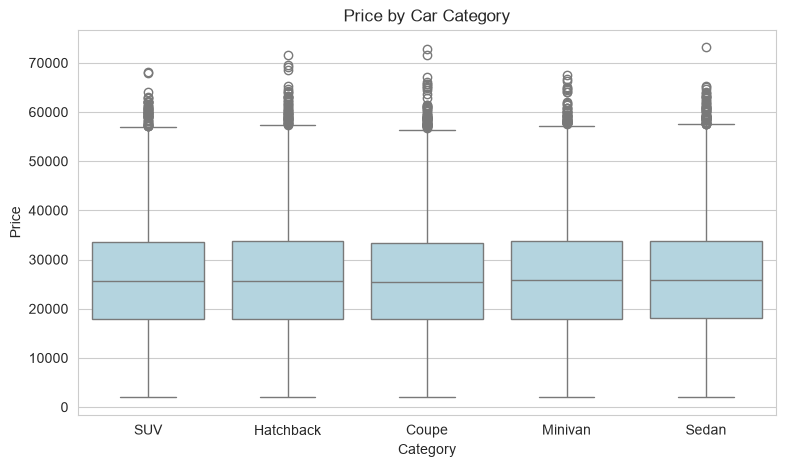

In [10]:
plt.figure(figsize=(9, 5))
sns.boxplot(x="Category", y="Price", data=df, color="lightblue")
plt.title("Price by Car Category")
plt.show()

**Insight:** All categories have almost the same price range, so `Category` is not a strong feature.

## 11. Does leather interior or gearbox type change the price?

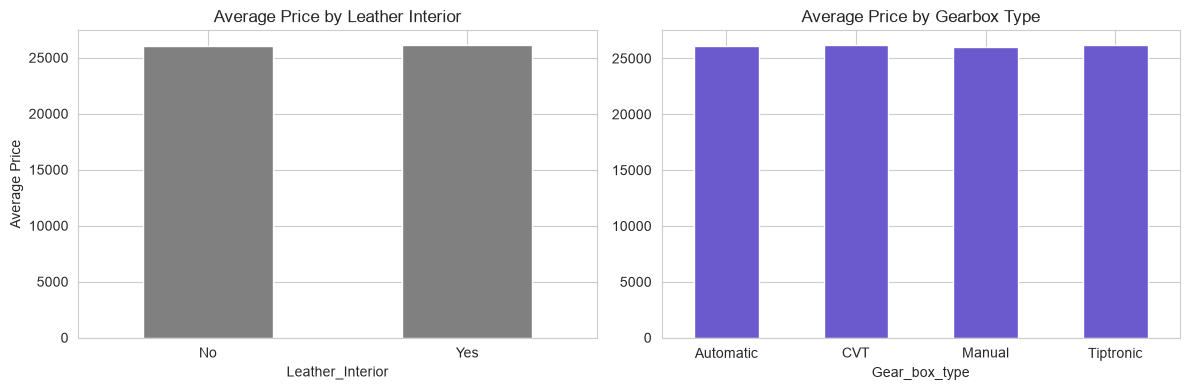

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

df.groupby("Leather_Interior")["Price"].mean().plot(kind="bar", ax=axes[0], color="gray")
axes[0].set_title("Average Price by Leather Interior")
axes[0].set_ylabel("Average Price")
axes[0].tick_params(axis="x", rotation=0)

df.groupby("Gear_box_type")["Price"].mean().plot(kind="bar", ax=axes[1], color="slateblue")
axes[1].set_title("Average Price by Gearbox Type")
axes[1].tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()

**Insight:** The bars are almost equal, so these two features barely change the price.

## 12. Correlation heatmap
Correlation shows how strongly two number columns move together (from -1 to +1).

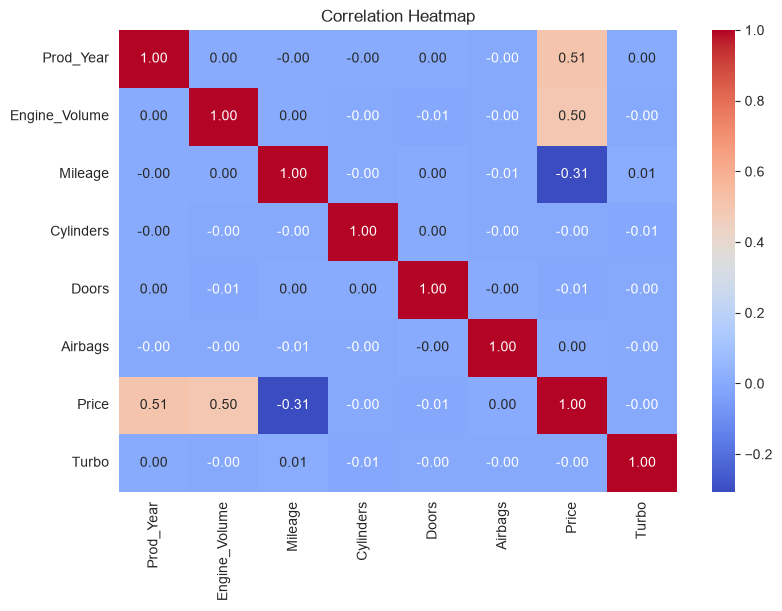

In [12]:
plt.figure(figsize=(9, 6))
sns.heatmap(df.corr(numeric_only=True), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.show()

## 13. Summary of what we learned

- **Strong effect on price:** Manufacturer (BMW / Mercedes-Benz), Fuel type (Electric), Production year, Engine volume, Mileage (negative)
- **Almost no effect on price:** Category, Color, Doors, Airbags, Cylinders, Leather interior, Gearbox, Drive wheels

Next: open `03_ml_model.ipynb` to train the models.